# ItemCF 基线与电影推荐演示

本 Notebook 展示已实现的正反馈 ItemCF：训练相似度、验证集调参、选定配置的最终测试，以及按用户 ID 生成带解释的电影推荐。复用 `01_data_analysis.ipynb` 的划分、标签、候选和评估用户。

先在项目根目录运行 `python train.py --model itemcf`。本 Notebook 读取保存的结果，不会自动重复训练或测试；修改第 5 节的用户 ID 后可生成新的推荐。

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

PROJECT_ROOT = next((path for path in [Path.cwd(), *Path.cwd().parents]
                     if (path / 'src' / 'models' / 'item_cf.py').is_file()), None)
if PROJECT_ROOT is None:
    raise RuntimeError('请从项目根目录或 notebooks 目录启动。')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src.recommend import file_sha256, recommend_for_user

%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid')
TABLE_DIR = PROJECT_ROOT / 'outputs' / 'tables'
MODEL_DIR = PROJECT_ROOT / 'outputs' / 'models' / 'itemcf'
PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
FIGURE_DIR = PROJECT_ROOT / 'outputs' / 'figures'
print(f'Project: {PROJECT_ROOT}')

Project: E:\港城莞\课程资料\研一 SemA\CS5481 Data Engineer\data_engineer_group_project


## 1. 算法原理与选定配置

训练输入是评分至少 4 分的二值正反馈矩阵 $B$。电影共现矩阵为 $C=B^TB$，电影支持数为 $f_i=C_{ii}$。对存在共现的不同电影计算：

$$s_{ij}=\frac{C_{ij}}{\sqrt{f_i f_j}}\frac{C_{ij}}{C_{ij}+\lambda}.$$

$\lambda=0$ 时为普通余弦相似度。自身相似度设为 0；每部来源电影仅保留最相似的 $K$ 个邻居，因此最终邻居矩阵可能不对称。候选电影分数为：

$$score(u,j)=\sum_{i\in H_u^+}s_{ij}.$$

$H_u^+$ 是推荐时允许看到的正反馈历史。该分数用于排序，不是 1–5 分的预测。低分电影仍在已评分过滤历史中。

这里的邻居数 $K$ 与“推荐前 5/10 部电影”的截断数量是两个不同参数。相似度完全根据训练集拟合，电影类型和人口属性不参与该基线。

In [2]:
run_path = TABLE_DIR / 'itemcf_run.json'
if not run_path.is_file() or not (MODEL_DIR / 'run.json').is_file():
    raise FileNotFoundError('请先运行 python train.py --model itemcf。')
run = json.loads(run_path.read_text(encoding='utf-8'))
for filename, checksum in run['input_sha256'].items():
    if file_sha256(PROCESSED_DIR / filename) != checksum:
        raise ValueError(f'预处理输入已变化：{filename}；请重新运行基线。')
display(pd.DataFrame([run['selected_parameters']]))
display(Markdown(
    f'**选定方式：**{run["selection_metric"]}。选定邻居数为 '
    f'**{run["selected_parameters"]["n_neighbors"]}**，收缩参数为 '
    f'**{run["selected_parameters"]["shrinkage"]:g}**。'
    f'选定参数这一次拟合耗时 **{run["fit_seconds_selected_trial"]:.2f} 秒**，'
    '模型参数未使用验证或测试交互拟合。'
))

,n_neighbors,shrinkage
0,50,0.0


**选定方式：**NDCG@10 on validation。选定邻居数为 **50**，收缩参数为 **0**。选定参数这一次拟合耗时 **1.57 秒**，模型参数未使用验证或测试交互拟合。

## 2. 验证集参数搜索

默认比较 3 种邻居数量和 3 种收缩参数，共 9 个配置。主选择指标为验证 NDCG@10；同分时依次比较 Recall@10、较小邻居数和较小收缩参数。所有配置使用同一验证用户与完整候选规则。测试集不参与这些选择。

,n_neighbors,shrinkage,fit_seconds,validation_seconds,users,Recall@5,NDCG@5,CatalogCoverage@5,Recall@10,NDCG@10,CatalogCoverage@10,selected
0,20,0.000000,0.81,2.30,5776,0.0470,0.0769,0.107172,0.0825,0.0842,0.156804,False
1,20,10.000000,1.50,4.09,5776,0.0453,0.0765,0.080720,0.0801,0.0835,0.116171,False
2,20,50.000000,1.73,3.41,5776,0.0428,0.0735,0.054268,0.0762,0.0805,0.080175,False
3,50,0.000000,1.57,4.16,5776,0.0457,0.0782,0.094082,0.0789,0.0844,0.131443,True
4,50,10.000000,1.67,4.67,5776,0.0445,0.0767,0.063812,0.0770,0.0827,0.092446,False
5,50,50.000000,1.76,4.72,5776,0.0403,0.0722,0.042542,0.0734,0.0790,0.060813,False
6,100,0.000000,1.63,4.87,5776,0.0448,0.0771,0.078538,0.0774,0.0831,0.113172,False
7,100,10.000000,1.94,4.86,5776,0.0438,0.0756,0.054540,0.0755,0.0812,0.075811,False
8,100,50.000000,1.75,4.49,5776,0.0407,0.0729,0.041996,0.0728,0.0789,0.055631,False


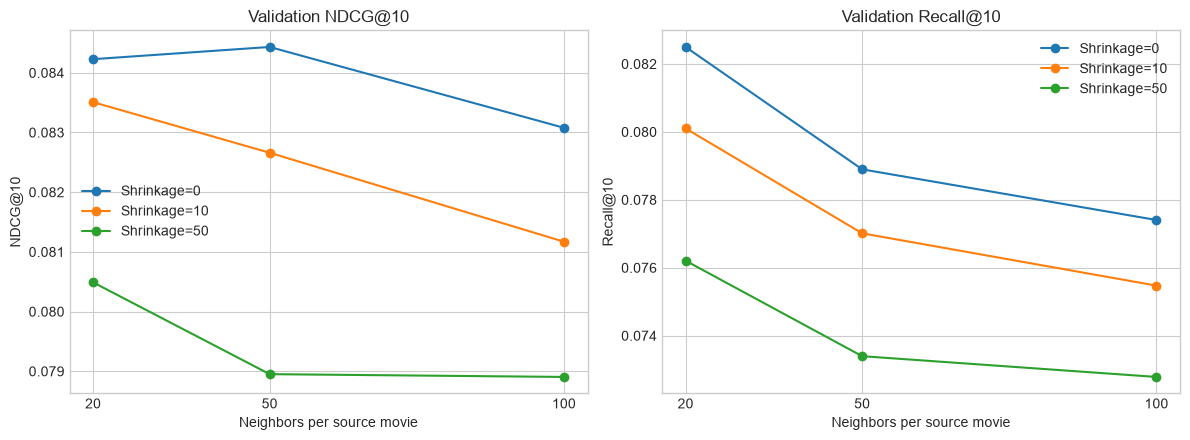

In [3]:
search = pd.read_csv(TABLE_DIR / 'itemcf_validation_search.csv')
display(search.style.format({'Recall@5': '{:.4f}', 'NDCG@5': '{:.4f}',
                            'Recall@10': '{:.4f}', 'NDCG@10': '{:.4f}',
                            'fit_seconds': '{:.2f}', 'validation_seconds': '{:.2f}'}))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for shrinkage, group in search.groupby('shrinkage', sort=True):
    group = group.sort_values('n_neighbors')
    for ax, metric in zip(axes, ['NDCG@10', 'Recall@10']):
        ax.plot(group['n_neighbors'], group[metric], marker='o', label=f'Shrinkage={shrinkage:g}')
        ax.set(xlabel='Neighbors per source movie', ylabel=metric, title=f'Validation {metric}')
        ax.set_xticks(sorted(search['n_neighbors'].unique()))
        ax.legend()
fig.tight_layout()
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(FIGURE_DIR / '09_itemcf_validation_search.png', dpi=180, bbox_inches='tight')
plt.show()
plt.close(fig)

## 3. 选定模型的验证与测试表现

使用相同的完整候选规则：训练目录减去该用户当时已评分的所有电影。同分按原始电影 ID 升序排列，零支持候选仍为零分。

Recall@K 为命中的正例数除以该用户全部可评估正例数；NDCG@K 同时考虑命中位置。指标按可评估用户宏平均。CatalogCoverage@K 为所有用户被推荐到的不同电影数占训练目录的比例。

Top-5 和 Top-10 是本项目的实验设置；课程硬性要求是至少推荐 5 部未评分电影。验证使用训练历史，测试使用训练加验证历史；模型相似度仍固定为训练集拟合结果。

In [4]:
metrics = pd.read_csv(TABLE_DIR / 'itemcf_metrics.csv')
metric_columns = [column for column in metrics if '@' in column]
display(metrics.style.format({column: '{:.4f}' for column in metric_columns}))
test_metrics = metrics.set_index('split').loc['test']
display(Markdown(
    f'**测试结果：**在 **{int(test_metrics["users"]):,}** 位共同可评估用户上，'
    f'Recall@10 为 **{test_metrics["Recall@10"]:.4f}**，'
    f'NDCG@10 为 **{test_metrics["NDCG@10"]:.4f}**。'
    '这些结果为后续 LightFM 与近期算法提供基线，尚不能说明哪种算法最佳。'
    '评估范围是预处理定义的已有用户、训练目录内正例，冷启动正例另行统计。'
))

,algorithm,split,users,Recall@5,NDCG@5,CatalogCoverage@5,Recall@10,NDCG@10,CatalogCoverage@10
0,ItemCF,validation,5776,0.0457,0.0782,0.0941,0.0789,0.0844,0.1314
1,ItemCF,test,5765,0.0414,0.0729,0.0848,0.0712,0.0773,0.1263


**测试结果：**在 **5,765** 位共同可评估用户上，Recall@10 为 **0.0712**，NDCG@10 为 **0.0773**。这些结果为后续 LightFM 与近期算法提供基线，尚不能说明哪种算法最佳。评估范围是预处理定义的已有用户、训练目录内正例，冷启动正例另行统计。

## 4. 基础误差分析

检查多少测试用户在前 10 名中没有命中，以及用户指标的分布。邻居相似度受训练交互稀疏与电影热度影响；平均指标之外，还需要后续比较长尾、短历史用户及具体推荐案例。

In [5]:
per_user = pd.read_csv(MODEL_DIR / 'test_per_user.csv')
zero_hit_users = int(per_user['Recall@10'].eq(0).sum())
display(per_user[['relevant_items', 'candidate_count', 'Recall@10', 'NDCG@10']].describe().round(4))
display(Markdown(
    f'**误差观察：**共有 **{zero_hit_users:,} / {len(per_user):,}** 位测试用户'
    f'（**{zero_hit_users / len(per_user):.2%}**）在 Top-10 中没有命中可评估正例。'
    '这是后续比较模型和分析失败案例的重要参考；不代表这些用户对所有推荐电影都不喜欢，'
    '因为大量候选电影并没有可观察评分。'
))

,relevant_items,candidate_count,Recall@10,NDCG@10
count,5765.0000,5765.0000,5765.0000,5765.0000
mean,8.9709,3513.7056,0.0712,0.0773
std,9.8512,175.6879,0.1527,0.1449
min,1.0000,1586.0000,0.0000,0.0000
25%,3.0000,3475.0000,0.0000,0.0000
50%,6.0000,3577.0000,0.0000,0.0000
75%,11.0000,3625.0000,0.0833,0.1070
max,117.0000,3655.0000,1.0000,1.0000


**误差观察：**共有 **3,849 / 5,765** 位测试用户（**66.76%**）在 Top-10 中没有命中可评估正例。这是后续比较模型和分析失败案例的重要参考；不代表这些用户对所有推荐电影都不喜欢，因为大量候选电影并没有可观察评分。

## 5. 按用户 ID 生成推荐

修改 `USER_ID`、`TOP_K` 后重新运行下面的单元格。`HISTORY_STAGE='test'` 使用测试期开始前的已知历史；`'validation'` 只使用训练历史。这是离线数据的推荐演示。

`because_title` 为贡献最大的已知喜欢电影，`because_similarity` 为其保留的相似度贡献；总推荐分数还可能累加其他历史电影的贡献。已评分电影全部过滤，标题与类型从电影元数据读取。

In [6]:
USER_ID = 1
TOP_K = 10
HISTORY_STAGE = 'test'

recommendations = recommend_for_user(USER_ID, stage=HISTORY_STAGE, k=TOP_K)
display(recommendations[['rank', 'title', 'genres', 'score', 'because_title', 'because_similarity']]
        .style.format({'score': '{:.4f}', 'because_similarity': '{:.4f}'}))
print(f'User {USER_ID}: {len(recommendations)} unseen movie recommendations')

,rank,title,genres,score,because_title,because_similarity
0,1,Raiders of the Lost Ark (1981),Action|Adventure,10.8170,Star Wars: Episode IV - A New Hope (1977),0.6487
1,2,Star Wars: Episode V - The Empire Strikes Back (1980),Action|Adventure|Drama|Sci-Fi|War,10.2634,Star Wars: Episode IV - A New Hope (1977),0.7289
2,3,"Shawshank Redemption, The (1994)",Drama,9.5549,Schindler's List (1993),0.6051
3,4,"Silence of the Lambs, The (1991)",Drama|Thriller,8.4180,Fargo (1996),0.5792
4,5,Pulp Fiction (1994),Crime|Drama,6.7816,Fargo (1996),0.6188
5,6,American Beauty (1999),Comedy|Drama,6.4808,Fargo (1996),0.5260
6,7,Groundhog Day (1993),Comedy|Romance,6.3872,Toy Story (1995),0.4916
7,8,Stand by Me (1986),Adventure|Comedy|Drama,6.3493,Ferris Bueller's Day Off (1986),0.4551
8,9,Star Wars: Episode VI - Return of the Jedi (1983),Action|Adventure|Romance|Sci-Fi|War,6.2726,Star Wars: Episode IV - A New Hope (1977),0.6435
9,10,Shakespeare in Love (1998),Comedy|Romance,6.0314,"Sixth Sense, The (1999)",0.4387


User 1: 10 unseen movie recommendations


## 6. 固定用户案例与后续比较

下表按用户 ID 顺序选择前三位可评估测试用户，每人推荐 10 部电影，未按命中结果挑选用户。`relevant_in_test` 仅用于结果分析，在推荐分数计算完成后添加，不输入模型。

In [7]:
examples = pd.read_csv(TABLE_DIR / 'itemcf_recommendation_examples.csv')
display(examples[['user_id', 'rank', 'title', 'genres', 'because_title', 'relevant_in_test']])
example_hits = examples.groupby('user_id')['relevant_in_test'].sum().to_frame('hits_in_top10')
display(example_hits)

,user_id,rank,title,genres,because_title,relevant_in_test
0,1,1,Raiders of the Lost Ark (1981),Action|Adventure,Star Wars: Episode IV - A New Hope (1977),False
1,1,2,Star Wars: Episode V - The Empire Strikes Back...,Action|Adventure|Drama|Sci-Fi|War,Star Wars: Episode IV - A New Hope (1977),False
2,1,3,"Shawshank Redemption, The (1994)",Drama,Schindler's List (1993),False
3,1,4,"Silence of the Lambs, The (1991)",Drama|Thriller,Fargo (1996),False
4,1,5,Pulp Fiction (1994),Crime|Drama,Fargo (1996),False
5,1,6,American Beauty (1999),Comedy|Drama,Fargo (1996),False
6,1,7,Groundhog Day (1993),Comedy|Romance,Toy Story (1995),False
7,1,8,Stand by Me (1986),Adventure|Comedy|Drama,Ferris Bueller's Day Off (1986),False
8,1,9,Star Wars: Episode VI - Return of the Jedi (1983),Action|Adventure|Romance|Sci-Fi|War,Star Wars: Episode IV - A New Hope (1977),False
9,1,10,Shakespeare in Love (1998),Comedy|Romance,"Sixth Sense, The (1999)",False


,hits_in_top10
user_id,
1,0
2,0
3,0


本阶段已经跑通第一种推荐算法。后续算法复用同一数据划分、用户集合、候选和指标，模型选择继续依据验证集。

算法参考：Badrul Sarwar, George Karypis, Joseph Konstan, and John Riedl. 2001. [Item-based Collaborative Filtering Recommendation Algorithms](https://ra.ethz.ch/cdstore/www10/papers/519/sdm2.html)。本项目使用正反馈二值输入、可选相似度收缩和统一 Top-N 协议的具体实现。